# Abandono de clientes bancarios mediante regresión logística binaria


## 1. Caso

 El análisis usa un conjunto de datos didáctico de abandono bancario (*Churn Modelling*). **No representa una validación en una entidad bancaria real.**

**Pregunta:** ¿Cómo se relacionan la edad, el saldo, el estado de actividad y el país con la probabilidad de que un cliente abandone el banco?

**Variable respuesta:** `Abandono` (0 = permanece; 1 = abandona).



## 2. Librerías y ubicación de los archivos

Antes de ejecutar el cuaderno, guarde `Churn_Modelling.csv` en la misma carpeta que este `.ipynb`. La ruta relativa facilita compartir el proyecto sin modificar el nombre de usuario del computador. Las gráficas se guardan en la carpeta `Imagenes/`.

In [1]:
# 0. LIBRERIAS (instalar solo una vez si es necesario)
# pip install pandas numpy matplotlib statsmodels scikit-learn

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FixedFormatter, NullFormatter
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score
from IPython.display import display

# Paleta del proyecto y estilo general de las gráficas
NARANJA, MORADO, LILA = "#F47721", "#70218A", "#7B65AB"
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E6E6E6", "axes.axisbelow": True,
})

CARPETA_IMAGENES = "Imagenes"
os.makedirs(CARPETA_IMAGENES, exist_ok=True)

def guardar(fig, nombre):
    """Guarda la figura en alta resolución dentro de la carpeta Imagenes/."""
    fig.savefig(os.path.join(CARPETA_IMAGENES, f"{nombre}.png"),
                dpi=300, bbox_inches="tight", facecolor="white")

## 3. Importación y preparación de los datos

Eliminamos columnas identificadoras, revisamos valores faltantes y duplicados por identificador, cambiamos nombres al español y definimos las variables categóricas.

In [2]:
# 2. IMPORTACION Y PREPARACION DE DATOS
RUTA_DATOS = "Churn_Modelling.csv"   # ruta relativa: el CSV junto a este cuaderno
Datos = pd.read_csv(RUTA_DATOS)

print("Dimensiones:", Datos.shape)
print("Columnas:", list(Datos.columns))
Datos.info()

Dimensiones: (10000, 14)
Columnas: ['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non

In [3]:
# Resumen descriptivo de todas las variables
display(Datos.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
CustomerId,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
NumOfProducts,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0


In [4]:
# Revisar faltantes y clientes duplicados ANTES de retirar identificadores
print("Valores faltantes por columna:")
print(Datos.isna().sum())
print("\nClientes duplicados por CustomerId:", Datos["CustomerId"].duplicated().sum())

# Solo quitamos filas repetidas del mismo identificador; si las hay,
# conviene verificar que no representen movimientos distintos del cliente.
Datos = Datos.drop_duplicates(subset="CustomerId")

Valores faltantes por columna:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Clientes duplicados por CustomerId: 0


In [5]:
# Retirar identificadores y renombrar columnas
Datos = (
    Datos.drop(columns=["RowNumber", "CustomerId", "Surname"])
    .rename(columns={
        "CreditScore": "Puntaje_Credito",
        "Geography": "Pais",
        "Gender": "Genero",
        "Age": "Edad",
        "Tenure": "Antiguedad",
        "Balance": "Saldo",
        "NumOfProducts": "Num_Productos",
        "HasCrCard": "Tarjeta_Credito",
        "IsActiveMember": "Cliente_Activo",
        "EstimatedSalary": "Salario_Estimado",
        "Exited": "Abandono",
    })
)

# Variables categóricas con su categoría de referencia como PRIMER nivel
Datos["Pais"] = pd.Categorical(Datos["Pais"], categories=["France", "Germany", "Spain"])
Datos["Genero"] = Datos["Genero"].astype("category")
Datos["Cliente_Activo"] = pd.Categorical(
    Datos["Cliente_Activo"].map({0: "No", 1: "Si"}), categories=["No", "Si"]
)
Datos["Abandono"] = Datos["Abandono"].astype(int)
Datos["Saldo_10mil"] = Datos["Saldo"] / 10000   # saldo expresado en decenas de miles

# Datos completos para las variables del modelo
Datos_modelo = (
    Datos[["Abandono", "Edad", "Saldo", "Saldo_10mil", "Cliente_Activo", "Pais"]]
    .dropna()
    .reset_index(drop=True)
)
assert set(Datos_modelo["Abandono"].unique()) <= {0, 1}

estructura_tabla = pd.DataFrame({
    "Variable": Datos_modelo.columns,
    "Tipo_Dato": [str(t) for t in Datos_modelo.dtypes],
    "Valores_Ejemplo": [
        ", ".join(Datos_modelo[c].dropna().astype(str).head(3))
        for c in Datos_modelo.columns
    ],
})
print("Tabla 1: Variables utilizadas en el modelo")
display(estructura_tabla)
print(f"El conjunto limpio contiene {len(Datos_modelo):,} registros y "
      f"{Datos_modelo.shape[1]} variables para la fase de modelado.")

Tabla 1: Variables utilizadas en el modelo


,Variable,Tipo_Dato,Valores_Ejemplo
0,Abandono,int64,"1, 0, 1"
1,Edad,int64,"42, 41, 42"
2,Saldo,float64,"0.0, 83807.86, 159660.8"
3,Saldo_10mil,float64,"0.0, 8.380786, 15.966079999999998"
4,Cliente_Activo,category,"Si, Si, No"
5,Pais,category,"France, Spain, France"


El conjunto limpio contiene 10,000 registros y 6 variables para la fase de modelado.


## 4. Análisis exploratorio

In [6]:
# 3. ANALISIS EXPLORATORIO
# 3.1 Distribucion de la respuesta
tabla_abandono = (
    Datos_modelo["Abandono"].value_counts().sort_index()
    .rename_axis("Abandono").reset_index(name="n")
)
tabla_abandono["Grupo"] = np.where(tabla_abandono["Abandono"] == 1, "Abandono", "Permanece")
tabla_abandono["Porcentaje"] = (100 * tabla_abandono["n"] / tabla_abandono["n"].sum()).round(1)
print("Tabla 2: Distribución general del abandono")
display(tabla_abandono)

Tabla 2: Distribución general del abandono


,Abandono,n,Grupo,Porcentaje
0,0,7963,Permanece,79.6
1,1,2037,Abandono,20.4


In [7]:
# 3.2 Resumen descriptivo por grupo
tabla_resumen = (
    Datos_modelo.groupby("Abandono")
    .agg(Clientes=("Abandono", "size"),
         Edad_media=("Edad", "mean"),
         Edad_mediana=("Edad", "median"),
         Saldo_medio=("Saldo", "mean"))
    .round({"Edad_media": 1, "Saldo_medio": 0})
    .reset_index()
)
print("Tabla 3: Edad y saldo según abandono")
display(tabla_resumen)

Tabla 3: Edad y saldo según abandono


,Abandono,Clientes,Edad_media,Edad_mediana,Saldo_medio
0,0,7963,37.4,36.0,72745.0
1,1,2037,44.8,45.0,91109.0


In [8]:
# 3.3 Proporcion de abandono segun pais
tabla_pais = (
    Datos_modelo.groupby("Pais", observed=True)
    .agg(Clientes=("Abandono", "size"),
         Abandonos=("Abandono", "sum"),
         Porcentaje=("Abandono", lambda s: round(100 * s.mean(), 1)))
    .reset_index()
)
print("Tabla 4: Abandono por país")
display(tabla_pais)

# 3.4 Proporcion de abandono segun actividad
tabla_activo = (
    Datos_modelo.groupby("Cliente_Activo", observed=True)
    .agg(Clientes=("Abandono", "size"),
         Abandonos=("Abandono", "sum"),
         Porcentaje=("Abandono", lambda s: round(100 * s.mean(), 1)))
    .reset_index()
)
print("\nTabla 5: Abandono por actividad")
display(tabla_activo)

Tabla 4: Abandono por país


,Pais,Clientes,Abandonos,Porcentaje
0,France,5014,810,16.2
1,Germany,2509,814,32.4
2,Spain,2477,413,16.7



Tabla 5: Abandono por actividad


,Cliente_Activo,Clientes,Abandonos,Porcentaje
0,No,4849,1302,26.9
1,Si,5151,735,14.3


**Interpretación:** las tablas y gráficas permiten examinar diferencias descriptivas, sin atribuirles por sí solas causalidad.

### 4.1. Distribución general del abandono

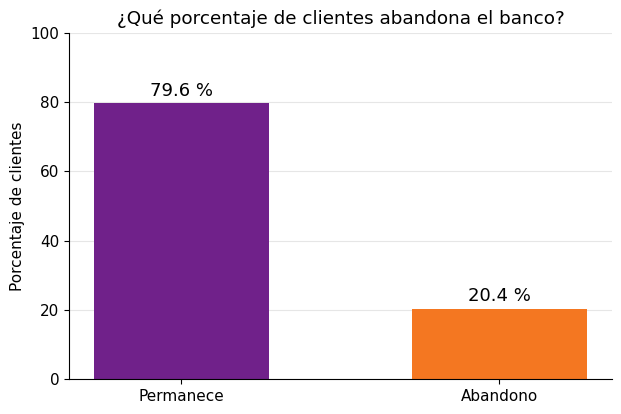

In [9]:
def etiquetar_barras(ax, barras, valores, sufijo=" %"):
    """Escribe el valor encima de cada barra vertical."""
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + ax.get_ylim()[1] * 0.01,
                f"{v}{sufijo}", ha="center", va="bottom", fontsize=13)

# Grafica 1: porcentaje general de abandono
colores = {"Abandono": NARANJA, "Permanece": MORADO}
fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(tabla_abandono["Grupo"], tabla_abandono["Porcentaje"], width=.55,
                color=[colores[g] for g in tabla_abandono["Grupo"]])
ax.set_ylim(0, 100)
etiquetar_barras(ax, barras, tabla_abandono["Porcentaje"])
ax.set_title("¿Qué porcentaje de clientes abandona el banco?")
ax.set_ylabel("Porcentaje de clientes")
ax.grid(axis="x", visible=False)
guardar(fig, "fig1_distribucion_abandono")
plt.show()

### 4.2. Diferencias por país

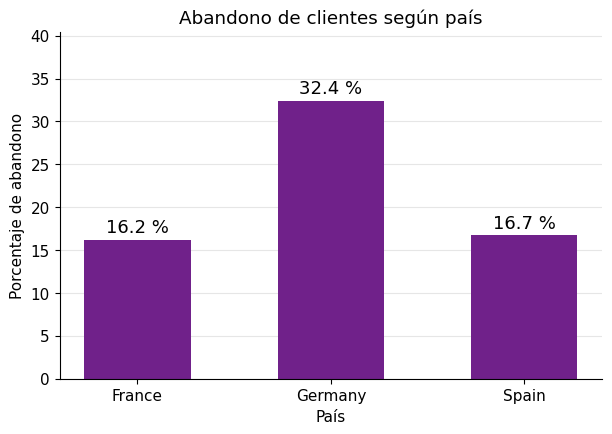

In [10]:
# Grafica 2: abandono por pais
fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(tabla_pais["Pais"].astype(str), tabla_pais["Porcentaje"], width=.55, color=MORADO)
ax.set_ylim(0, tabla_pais["Porcentaje"].max() + 8)
etiquetar_barras(ax, barras, tabla_pais["Porcentaje"])
ax.set_title("Abandono de clientes según país")
ax.set_xlabel("País"); ax.set_ylabel("Porcentaje de abandono")
ax.grid(axis="x", visible=False)
guardar(fig, "fig2_abandono_pais")
plt.show()

### 4.3. Diferencias según actividad

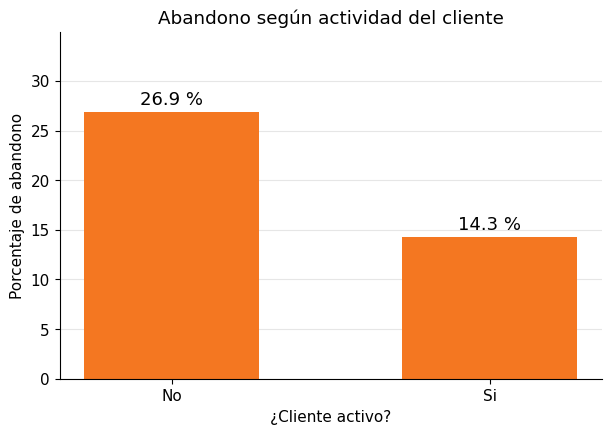

In [11]:
# Grafica 3: abandono por actividad
fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(tabla_activo["Cliente_Activo"].astype(str), tabla_activo["Porcentaje"],
                width=.55, color=NARANJA)
ax.set_ylim(0, tabla_activo["Porcentaje"].max() + 8)
etiquetar_barras(ax, barras, tabla_activo["Porcentaje"])
ax.set_title("Abandono según actividad del cliente")
ax.set_xlabel("¿Cliente activo?"); ax.set_ylabel("Porcentaje de abandono")
ax.grid(axis="x", visible=False)
guardar(fig, "fig3_abandono_actividad")
plt.show()

### 4.4. Distribución de edad según abandono

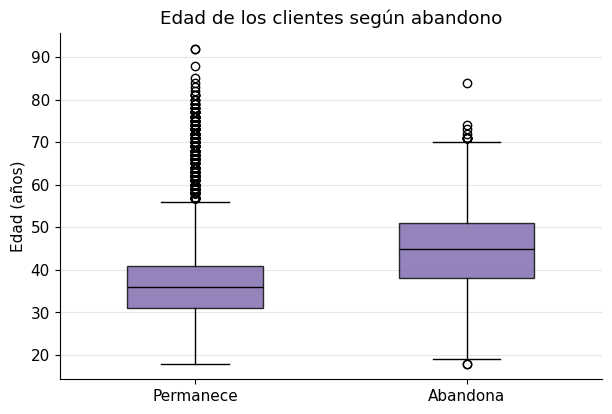

In [12]:
# Grafica 4: edad por abandono
fig, ax = plt.subplots(figsize=(7, 4.5))
grupos = [Datos_modelo.loc[Datos_modelo["Abandono"] == k, "Edad"] for k in (0, 1)]
caja = ax.boxplot(grupos, patch_artist=True, widths=.5)
for parche in caja["boxes"]:
    parche.set(facecolor=LILA, alpha=.8)
for mediana in caja["medians"]:
    mediana.set(color="black")
ax.set_xticks([1, 2])
ax.set_xticklabels(["Permanece", "Abandona"])
ax.set_title("Edad de los clientes según abandono")
ax.set_ylabel("Edad (años)")
ax.grid(axis="x", visible=False)
guardar(fig, "fig4_edad_abandono")
plt.show()

## 5. Partición estratificada: entrenamiento y prueba

Reservamos aproximadamente el 20 % de los registros para prueba. La estratificación busca mantener una proporción semejante de abandonos en ambos subconjuntos. La muestra de prueba no se usa para ajustar el modelo.

In [13]:
# 4. PARTICION ESTRATIFICADA: ENTRENAMIENTO Y PRUEBA
# test_size=2001 reproduce los tamaños del informe en R (7.999 entrenamiento / 2.001 prueba)
entrenamiento, prueba = train_test_split(
    Datos_modelo,
    test_size=2001,
    stratify=Datos_modelo["Abandono"],
    random_state=2026,
)
entrenamiento = entrenamiento.reset_index(drop=True)
prueba = prueba.reset_index(drop=True)

print("Entrenamiento:", len(entrenamiento), "filas")
print("Prueba:", len(prueba), "filas")

# Confirmar que la proporcion de abandono es similar
for nombre, df in [("Entrenamiento", entrenamiento), ("Prueba", prueba)]:
    tabla = df["Abandono"].value_counts().sort_index().rename("n").to_frame()
    tabla["Porcentaje"] = 100 * tabla["n"] / tabla["n"].sum()
    print(f"\n{nombre}:")
    display(tabla)

Entrenamiento: 7999 filas
Prueba: 2001 filas

Entrenamiento:


,n,Porcentaje
Abandono,,
0,6370,79.634954
1,1629,20.365046



Prueba:


,n,Porcentaje
Abandono,,
0,1593,79.610195
1,408,20.389805


## 6. Modelo lineal generalizado logístico

Como la respuesta tiene dos categorías, utilizamos una familia binomial con enlace logit:

$$\log\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1\,\text{Edad} + \beta_2\,\text{Saldo10mil} + \beta_3\,\text{Actividad} + \beta_4\,\text{País}$$

Las variables categóricas generan los coeficientes necesarios para las comparaciones con sus referencias (cliente inactivo y Francia). Para que los nombres de los coeficientes coincidan con los del informe en R, construimos la matriz de diseño con variables indicadoras explícitas.

In [14]:
# 6. AJUSTE DEL MODELO (SOLO EN ENTRENAMIENTO)
def matriz_diseno(df):
    """Matriz de diseño con intercepto y variables indicadoras.
    Referencias: Pais = France, Cliente_Activo = No."""
    X = pd.DataFrame({
        "Edad": df["Edad"].astype(float),
        "Saldo_10mil": df["Saldo_10mil"].astype(float),
        "Cliente_ActivoSi": (df["Cliente_Activo"] == "Si").astype(float),
        "PaisGermany": (df["Pais"] == "Germany").astype(float),
        "PaisSpain": (df["Pais"] == "Spain").astype(float),
    }, index=df.index)
    X.insert(0, "(Intercept)", 1.0)
    return X

X_ent = matriz_diseno(entrenamiento)
y_ent = entrenamiento["Abandono"]

modelo_logistico = sm.GLM(y_ent, X_ent, family=sm.families.Binomial()).fit()
print(modelo_logistico.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:               Abandono   No. Observations:                 7999
Model:                            GLM   Df Residuals:                     7993
Model Family:                Binomial   Df Model:                            5
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3465.9
Date:                Tue, 10 Nov 2026   Deviance:                       6931.8
Time:                        04:41:01   Pearson chi2:                 8.11e+03
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1343
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
(Intercept)         -4.2958      0.133  

In [15]:
# Tabla de coeficientes, odds ratios e intervalos de confianza del 95 % (Wald)
ic = modelo_logistico.conf_int()
tabla_modelo = pd.DataFrame({
    "term": modelo_logistico.params.index,
    "estimate": modelo_logistico.params.values,
    "std_error": modelo_logistico.bse.values,
    "statistic": modelo_logistico.tvalues.values,
    "p_value": modelo_logistico.pvalues.values,
    "conf_low": ic[0].values,
    "conf_high": ic[1].values,
})
tabla_modelo["OR"] = np.exp(tabla_modelo["estimate"])
tabla_modelo["OR_inf"] = np.exp(tabla_modelo["conf_low"])
tabla_modelo["OR_sup"] = np.exp(tabla_modelo["conf_high"])

print("Tabla 6: Coeficientes del modelo")
display(tabla_modelo.round(3))

Tabla 6: Coeficientes del modelo


,term,estimate,std_error,statistic,p_value,conf_low,conf_high,OR,OR_inf,OR_sup
0,(Intercept),-4.296,0.133,-32.330,0.000,-4.556,-4.035,0.014,0.011,0.018
1,Edad,0.072,0.003,25.146,0.000,0.066,0.077,1.074,1.068,1.080
2,Saldo_10mil,0.028,0.006,5.018,0.000,0.017,0.039,1.028,1.017,1.039
3,Cliente_ActivoSi,-1.092,0.064,-16.972,0.000,-1.218,-0.966,0.336,0.296,0.381
4,PaisGermany,0.804,0.074,10.805,0.000,0.658,0.950,2.234,1.931,2.585
5,PaisSpain,0.018,0.079,0.224,0.823,-0.137,0.172,1.018,0.872,1.188


## 7. Significancia y odds ratios

In [16]:
# 7. SIGNIFICANCIA ESTADISTICA (ENTRENAMIENTO)
sin_intercepto = tabla_modelo[tabla_modelo["term"] != "(Intercept)"]
significativas = sin_intercepto.loc[sin_intercepto["p_value"] < 0.05, "term"].tolist()
no_significativas = sin_intercepto.loc[sin_intercepto["p_value"] >= 0.05, "term"].tolist()
print("Significativas (p < 0,05):", significativas)
print("No significativas:", no_significativas)

# 8. ODDS RATIOS (ENTRENAMIENTO)
tabla_or = pd.DataFrame({
    "Variable": sin_intercepto["term"].values,
    "Coeficiente": sin_intercepto["estimate"].round(3).values,
    "OR": sin_intercepto["OR"].round(3).values,
    "IC_95_inferior": sin_intercepto["OR_inf"].round(3).values,
    "IC_95_superior": sin_intercepto["OR_sup"].round(3).values,
    "Valor_p": sin_intercepto["p_value"].map(lambda v: float(f"{v:.3g}")).values,
})
print("\nTabla 7: Odds ratios ajustados e intervalos de confianza")
display(tabla_or)

Significativas (p < 0,05): ['Edad', 'Saldo_10mil', 'Cliente_ActivoSi', 'PaisGermany']
No significativas: ['PaisSpain']

Tabla 7: Odds ratios ajustados e intervalos de confianza


,Variable,Coeficiente,OR,IC_95_inferior,IC_95_superior,Valor_p
0,Edad,0.072,1.074,1.068,1.080,1.560000e-139
1,Saldo_10mil,0.028,1.028,1.017,1.039,5.230000e-07
2,Cliente_ActivoSi,-1.092,0.336,0.296,0.381,1.320000e-64
3,PaisGermany,0.804,2.234,1.931,2.585,3.260000e-27
4,PaisSpain,0.018,1.018,0.872,1.188,8.230000e-01


Un odds ratio mayor que 1 representa mayores odds de abandono, y uno menor que 1, menores odds, bajo el modelo ajustado y manteniendo constantes las demás variables. Los coeficientes son asociaciones, no efectos causales.

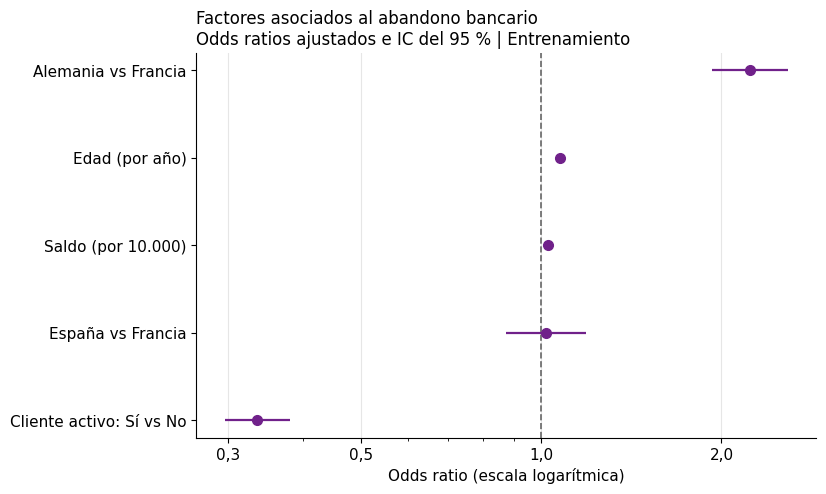

In [17]:
# Grafica 5: odds ratios ajustados con IC 95 %
etiquetas = {
    "Edad": "Edad (por año)",
    "Saldo_10mil": "Saldo (por 10.000)",
    "Cliente_ActivoSi": "Cliente activo: Sí vs No",
    "PaisGermany": "Alemania vs Francia",
    "PaisSpain": "España vs Francia",
}
d = sin_intercepto.assign(Variable=sin_intercepto["term"].map(etiquetas)).sort_values("OR")

fig, ax = plt.subplots(figsize=(8, 5))
ax.axvline(1, ls="--", color="#666666", lw=1.2)
y = np.arange(len(d))
ax.errorbar(d["OR"], y,
            xerr=[d["OR"] - d["OR_inf"], d["OR_sup"] - d["OR"]],
            fmt="o", color=MORADO, ecolor=MORADO, elinewidth=1.6, markersize=7, capsize=0)
ax.set_yticks(y)
ax.set_yticklabels(d["Variable"])
ax.set_xscale("log")
marcas = [0.3, 0.5, 1, 2]
ax.set_xticks(marcas)
ax.xaxis.set_major_formatter(FixedFormatter(["0,3", "0,5", "1,0", "2,0"]))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Odds ratio (escala logarítmica)")
ax.set_title("Factores asociados al abandono bancario\n"
             "Odds ratios ajustados e IC del 95 % | Entrenamiento", loc="left", fontsize=12)
ax.grid(axis="y", visible=False)
guardar(fig, "fig5_odds_ratios")
plt.show()

## 8. Evaluación del ajuste en entrenamiento

In [18]:
# 9. EVALUACION DEL AJUSTE (EN ENTRENAMIENTO)
dev_nula = modelo_logistico.null_deviance
dev_resid = modelo_logistico.deviance
aic_val = modelo_logistico.aic
pseudo_r2 = 1 - modelo_logistico.llf / modelo_logistico.llnull   # McFadden

tabla_ajuste = pd.DataFrame({
    "Metrica": ["Devianza nula", "Devianza residual", "AIC", "Pseudo R2 de McFadden"],
    "Valor": np.round([dev_nula, dev_resid, aic_val, pseudo_r2], 3),
})
print("Tabla 8: Medidas de ajuste en entrenamiento")
display(tabla_ajuste)
print(f"Reducción de la devianza: {100 * (1 - dev_resid / dev_nula):.1f} %")

Tabla 8: Medidas de ajuste en entrenamiento


,Metrica,Valor
0,Devianza nula,8085.734
1,Devianza residual,6931.823
2,AIC,6943.823
3,Pseudo R2 de McFadden,0.143


Reducción de la devianza: 14.3 %


La devianza y el AIC informan sobre el ajuste y permiten comparar modelos apropiados sobre los mismos datos. El pseudo-R² de McFadden **no** se interpreta como porcentaje de varianza explicada.

## 9. Probabilidades estimadas según perfiles

Se comparan perfiles hipotéticos manteniendo constante el saldo en la mediana del entrenamiento. Las bandas son intervalos de confianza aproximados del 95 % calculados en la escala del enlace y transformados con la función logística.

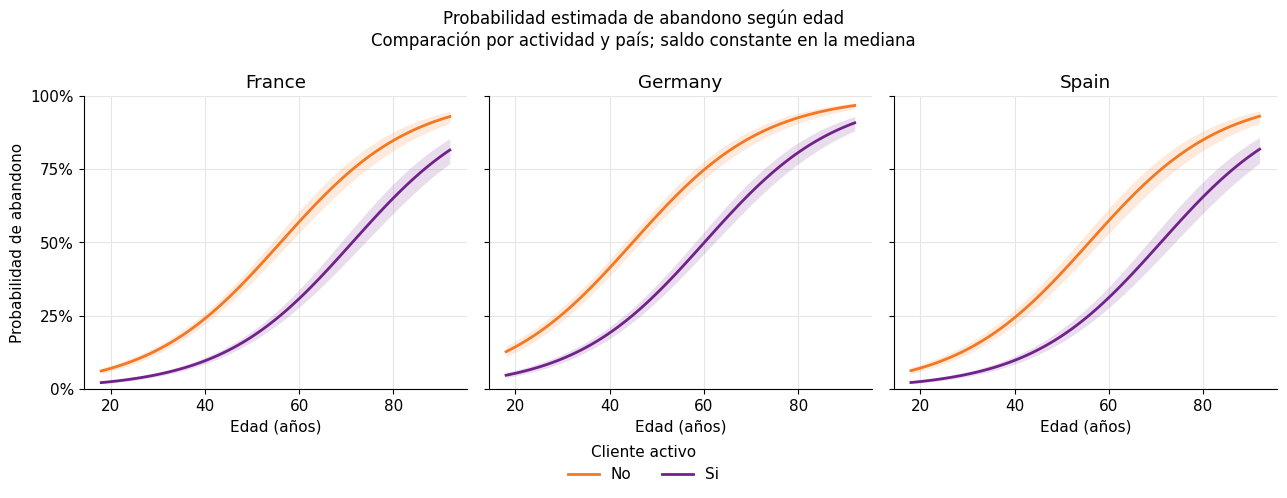

In [19]:
# 10. VISUALIZACION DE PROBABILIDADES ESTIMADAS
edades = np.linspace(entrenamiento["Edad"].min(), entrenamiento["Edad"].max(), 100)
saldo_mediano = entrenamiento["Saldo_10mil"].median()

nuevos_datos = pd.concat([
    pd.DataFrame({"Edad": edades, "Saldo_10mil": saldo_mediano,
                  "Cliente_Activo": act, "Pais": pais})
    for pais in ["France", "Germany", "Spain"]
    for act in ["No", "Si"]
], ignore_index=True)

X_nuevos = matriz_diseno(nuevos_datos)
beta = modelo_logistico.params.values
cov = modelo_logistico.cov_params().values
eta = X_nuevos.values @ beta                                   # predictor lineal
se_eta = np.sqrt(np.einsum("ij,jk,ik->i", X_nuevos.values, cov, X_nuevos.values))

logistica = lambda z: 1 / (1 + np.exp(-z))
nuevos_datos["Probabilidad"] = logistica(eta)
nuevos_datos["Limite_Inferior"] = logistica(eta - 1.96 * se_eta)
nuevos_datos["Limite_Superior"] = logistica(eta + 1.96 * se_eta)

# Grafica 6: probabilidad estimada segun edad, actividad y pais
fig, ejes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)
colores_act = {"No": NARANJA, "Si": MORADO}
for ax, pais in zip(ejes, ["France", "Germany", "Spain"]):
    for act in ["No", "Si"]:
        s = nuevos_datos[(nuevos_datos["Pais"] == pais) & (nuevos_datos["Cliente_Activo"] == act)]
        ax.fill_between(s["Edad"], s["Limite_Inferior"], s["Limite_Superior"],
                        color=colores_act[act], alpha=.15, lw=0)
        ax.plot(s["Edad"], s["Probabilidad"], color=colores_act[act], lw=2, label=act)
    ax.set_title(pais)
    ax.set_xlabel("Edad (años)")
    ax.set_ylim(0, 1)
ejes[0].set_ylabel("Probabilidad de abandono")
ejes[0].set_yticks(np.linspace(0, 1, 5))
ejes[0].set_yticklabels([f"{int(v*100)}%" for v in np.linspace(0, 1, 5)])
handles, labels = ejes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Cliente activo", loc="lower center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, -0.1))
fig.suptitle("Probabilidad estimada de abandono según edad\n"
             "Comparación por actividad y país; saldo constante en la mediana", fontsize=12)
fig.tight_layout()
guardar(fig, "fig6_probabilidades_perfiles")
plt.show()

## 10. Evaluación con datos de prueba

Aplicamos el modelo entrenado a observaciones no utilizadas para calcular los coeficientes. Con un umbral de 0,50, las probabilidades se convierten en clases predichas.

In [20]:
# 11. EVALUACION CON DATOS DE PRUEBA
# No se utiliza 'prueba' para ajustar coeficientes ni elegir variables.
X_prue = matriz_diseno(prueba)
prueba["Probabilidad"] = modelo_logistico.predict(X_prue)
UMBRAL = 0.50
prueba["Prediccion"] = (prueba["Probabilidad"] >= UMBRAL).astype(int)

# Matriz: filas = real, columnas = predicho
matriz = (
    pd.crosstab(prueba["Abandono"], prueba["Prediccion"])
    .reindex(index=[0, 1], columns=[0, 1], fill_value=0)
)
matriz.index.name, matriz.columns.name = "Real", "Predicho"
print("Tabla 9: Matriz de confusión (prueba)")
display(matriz)

VN, FP = int(matriz.loc[0, 0]), int(matriz.loc[0, 1])
FN, VP = int(matriz.loc[1, 0]), int(matriz.loc[1, 1])

exactitud = (VP + VN) / matriz.values.sum()
sensibilidad = VP / (VP + FN) if (VP + FN) > 0 else np.nan
especificidad = VN / (VN + FP) if (VN + FP) > 0 else np.nan
precision = VP / (VP + FP) if (VP + FP) > 0 else np.nan
f1 = (2 * precision * sensibilidad / (precision + sensibilidad)
      if np.isfinite(precision) and np.isfinite(sensibilidad) and (precision + sensibilidad) > 0
      else np.nan)

# AUC ROC en la muestra de prueba
auc_val = roc_auc_score(prueba["Abandono"], prueba["Probabilidad"])

tabla_evaluacion = pd.DataFrame({
    "Indicador": ["Exactitud", "Sensibilidad", "Especificidad", "Precision", "F1", "AUC ROC"],
    "Valor": [exactitud, sensibilidad, especificidad, precision, f1, auc_val],
})
tabla_evaluacion["Porcentaje"] = (tabla_evaluacion["Valor"] * 100).round(1)
print("\nTabla 10: Indicadores de clasificación en prueba")
display(tabla_evaluacion.round({"Valor": 3}))

Tabla 9: Matriz de confusión (prueba)


Predicho,0,1
Real,,
0,1561,32
1,327,81



Tabla 10: Indicadores de clasificación en prueba


,Indicador,Valor,Porcentaje
0,Exactitud,0.821,82.1
1,Sensibilidad,0.199,19.9
2,Especificidad,0.980,98.0
3,Precision,0.717,71.7
4,F1,0.311,31.1
5,AUC ROC,0.749,74.9


**Lectura clave:** la exactitud mide el porcentaje de clasificaciones correctas; la sensibilidad mide la detección de abandonos reales; la especificidad mide la detección de permanencias reales. La curva ROC y su AUC resumen la discriminación a través de distintos umbrales.

### 10.1. Matriz de confusión en prueba

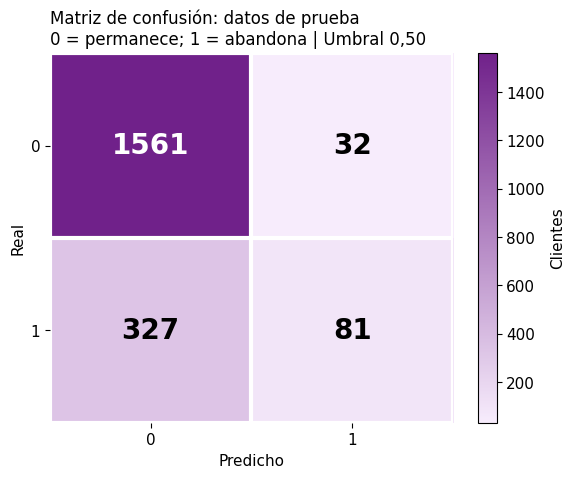

In [21]:
# Grafica 7: matriz de confusion
mapa = LinearSegmentedColormap.from_list("morado", ["#F7ECFC", MORADO])
fig, ax = plt.subplots(figsize=(6.5, 4.8))
im = ax.imshow(matriz.values, cmap=mapa, aspect="auto")
for i in range(2):
    for j in range(2):
        valor = matriz.values[i, j]
        color = "white" if valor > matriz.values.max() * 0.6 else "black"
        ax.text(j, i, f"{valor:,}".replace(",", ""), ha="center", va="center",
                fontsize=20, fontweight="bold", color=color)
ax.set_xticks([0, 1]); ax.set_xticklabels(["0", "1"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["0", "1"])
ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
ax.set_xticks(np.arange(-.5, 2, 1), minor=True); ax.set_yticks(np.arange(-.5, 2, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=3); ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
fig.colorbar(im, ax=ax, label="Clientes")
ax.set_title(f"Matriz de confusión: datos de prueba\n0 = permanece; 1 = abandona | Umbral {UMBRAL:.2f}".replace(".", ","),
             loc="left", fontsize=12)
guardar(fig, "fig7_matriz_confusion")
plt.show()

### 10.2. Curva ROC en prueba

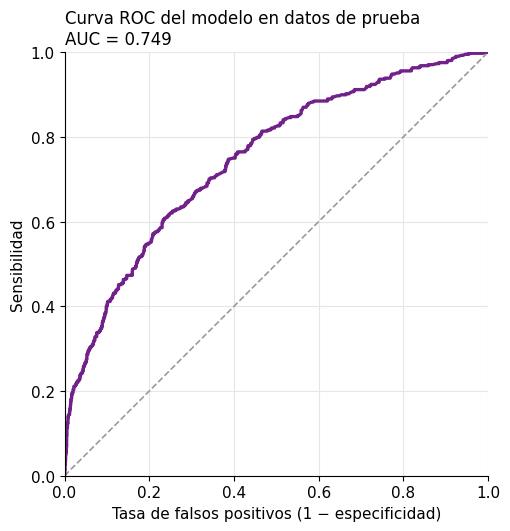

In [22]:
# Grafica 8: curva ROC
tasa_fp, tasa_vp, _ = roc_curve(prueba["Abandono"], prueba["Probabilidad"])

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], ls="--", color="#9A9A9A", lw=1.2)
ax.plot(tasa_fp, tasa_vp, color=MORADO, lw=2.4)
ax.set_aspect("equal")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Tasa de falsos positivos (1 − especificidad)")
ax.set_ylabel("Sensibilidad")
ax.set_title(f"Curva ROC del modelo en datos de prueba\nAUC = {auc_val:.3f}", loc="left", fontsize=12)
guardar(fig, "fig8_curva_roc")
plt.show()

### 10.3. Indicadores de clasificación en prueba

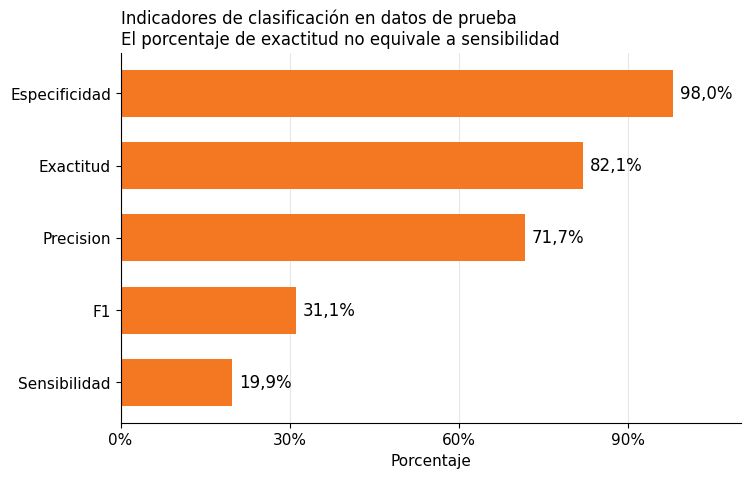

In [23]:
# Grafica 9: indicadores del modelo en datos de prueba
ind = tabla_evaluacion[tabla_evaluacion["Indicador"] != "AUC ROC"].sort_values("Valor")

fig, ax = plt.subplots(figsize=(8, 4.8))
barras = ax.barh(ind["Indicador"], ind["Valor"], color=NARANJA, height=.65)
for b, v in zip(barras, ind["Valor"]):
    ax.text(v + 0.012, b.get_y() + b.get_height() / 2, f"{v * 100:.1f}%".replace(".", ","),
            va="center", fontsize=12)
ax.set_xlim(0, 1.1)
ax.set_xticks([0, .3, .6, .9]); ax.set_xticklabels(["0%", "30%", "60%", "90%"])
ax.set_xlabel("Porcentaje")
ax.set_title("Indicadores de clasificación en datos de prueba\n"
             "El porcentaje de exactitud no equivale a sensibilidad", loc="left", fontsize=12)
ax.grid(axis="y", visible=False)
guardar(fig, "fig9_indicadores_clasificacion")
plt.show()

In [24]:
print(f"En la muestra de prueba, la exactitud fue {exactitud:.1%}, la sensibilidad {sensibilidad:.1%}, "
      f"la especificidad {especificidad:.1%} y el AUC {auc_val:.3f}.")

En la muestra de prueba, la exactitud fue 82.1%, la sensibilidad 19.9%, la especificidad 98.0% y el AUC 0.749.


## 11. Conclusiones y proyección

El modelo permite relacionar la edad, el saldo, el estado de actividad y el país con los odds de abandono. La evaluación con datos separados muestra resultados más informativos que evaluar el mismo conjunto utilizado en el ajuste.

**Limitaciones:** se realiza una sola partición entrenamiento/prueba; el umbral de 0,50 no fue optimizado; las observaciones del dataset no permiten inferir causalidad ni garantizar resultados en otro banco.

**Proyección:** en un trabajo posterior puede evaluarse la selección del umbral mediante validación cruzada dentro del entrenamiento (por ejemplo, con `StratifiedKFold` de `scikit-learn`), reservando la prueba para la evaluación final, y comparar la regresión logística con otros modelos como bosque aleatorio y árboles de clasificación.

**Aporte del proyecto de aula:** aprender a preparar datos, ajustar e interpretar un modelo estadístico, evaluar su desempeño y comunicar resultados mediante un cuaderno reproducible.